# downloading some extra packages

In [1]:
%%capture
!pip install tensorflow-gpu
!pip install livelossplot

# Import 

In [2]:
import tensorflow as tf
from PIL import Image
import cv2
import random 
import IPython
import functools
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import os
import io
from keras.utils import load_img, img_to_array


import tensorflow_datasets as tfds
from IPython.display import clear_output
from keras.utils.vis_utils import plot_model
from livelossplot import PlotLosses
import torch
%matplotlib inline

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# Check device type

In [3]:
print("Num GPUs Available: ", len(tf.config.experimental.list_physical_devices('GPU')))
# Limit TensorFlow to only use the first GPU
physical_devices = tf.config.experimental.list_physical_devices('GPU')
if len(physical_devices) > 0:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)

Num GPUs Available:  1


# Load all (image, mask) names

In [4]:
# Use tf.data.Dataset.list_files to get file paths directly from the directories
img_dir = "/kaggle/input/mapillaryvistasval/validation/images"
mask_dir = "/kaggle/input/mapillaryvistasval/validation/v1.2/labels"
imgs = sorted([os.path.join(img_dir, img) for img in os.listdir(img_dir)])
masks = sorted([os.path.join(mask_dir, img) for img in os.listdir(mask_dir)])

data_files_images = tf.data.Dataset.from_tensor_slices(imgs)
data_files_masks = tf.data.Dataset.from_tensor_slices(masks)

# splitting dataset to train, test and val

In [5]:

# Split the dataset
tr_size = int(len(data_files_images) * 0.9)
tr_imgs = data_files_images.take(tr_size)
tr_masks = data_files_masks.take(tr_size)
val_imgs = data_files_images.skip(tr_size)
val_masks = data_files_masks.skip(tr_size)

# Define and Run Image pre-processing

In [6]:
# preprocess an image and its mask
def process_img_mask(img_path, mask_path):
#     print(f"image type : {type(image)}")
    
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, (128, 128), method = tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    mask -= 1
    
    image = tf.io.read_file(img_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (128, 128))
    image = tf.cast(image, tf.float32) / 255.0
    

    random_flip_layer = tf.keras.layers.RandomFlip(mode="horizontal", seed=random.randint(0, 2000))
    image = random_flip_layer(image)
    mask = random_flip_layer(mask)
        
    image = tf.image.convert_image_dtype(image, dtype=tf.float32)
    mask = tf.image.convert_image_dtype(mask, dtype=tf.float32)
    return (image, mask)

# Map the function to load and preprocess the data
train_ds = tf.data.Dataset.zip((tr_imgs, tr_masks))
train_ds = train_ds.map(lambda im, m: tf.py_function(process_img_mask, [im,m], Tout=[tf.float32, tf.float32]), num_parallel_calls=tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.zip((val_imgs, val_masks))
train_ds = val_ds.map(lambda im, m: tf.py_function(process_img_mask, [im,m], Tout=[tf.float32, tf.float32]), num_parallel_calls=tf.data.AUTOTUNE)

# building Data loaders

In [7]:
# Cache, shuffle, batch, and prefetch datasets as before
BUFFER_SIZE = 1000
BATCH_SIZE = 32

train_batches = (
     train_ds
    .cache()
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .repeat()
    .prefetch(buffer_size=tf.data.AUTOTUNE))

val_batches = (
     val_ds
    .cache()
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .repeat()
    .prefetch(buffer_size=tf.data.AUTOTUNE))

# Testing Dataloaders

image batch dim : (32, 128, 128, 3)
mask batch dim : (32, 128, 128, 1)


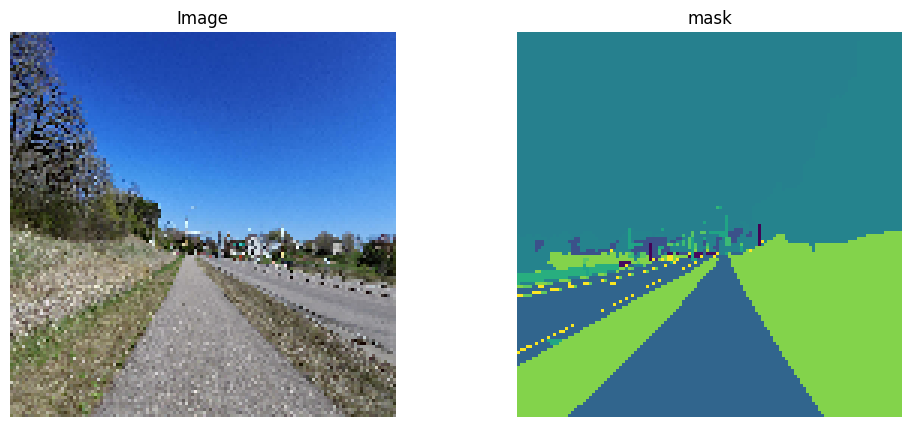

In [8]:
# Now, you can use train_ds and val_ds to train your segmentation model
for img_batch, mask_batch in train_batches:
    print(f"image batch dim : {img_batch.shape}")
    print(f"mask batch dim : {mask_batch.shape}")
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img_batch[0])
    plt.title('Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(mask_batch[0])
    plt.title('mask')
    plt.axis('off')  
    plt.show()
    break

# dispaly functions

In [9]:
def display(display_list):
    plt.figure(figsize=(15, 15))
    title = ['Input', 'True Mask', 'Pred Mask']
    for i in range(len(display_list)):
        plt.subplot(1, len(display_list), i+1)
        plt.title(title[i])
        plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
        plt.axis('off')
    plt.show()

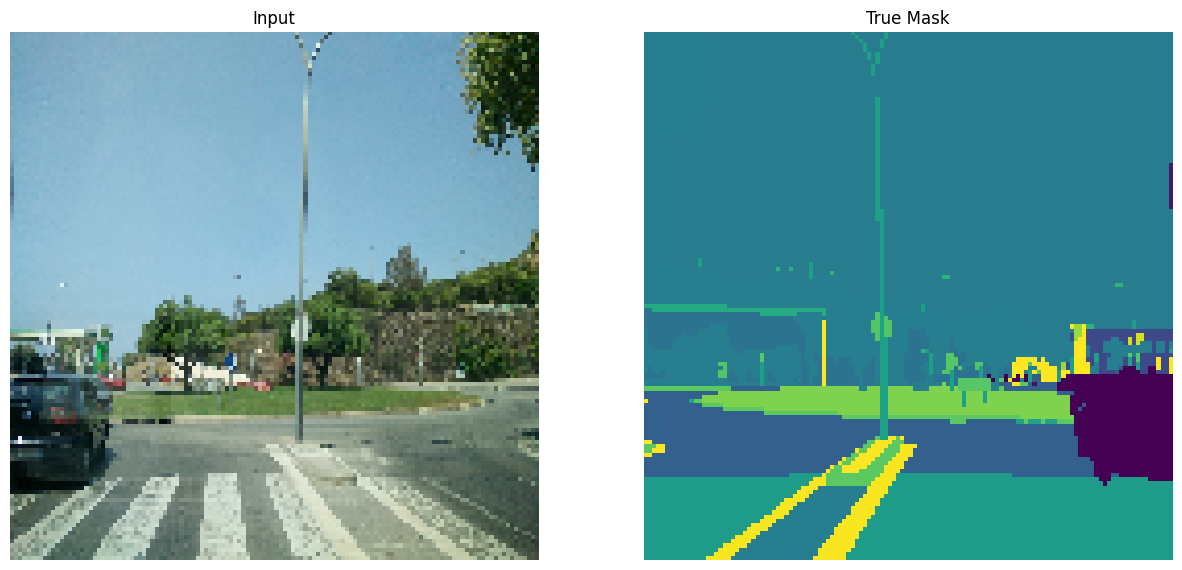

In [10]:
for images, masks in train_batches.take(1):
    s_img, s_mask = images[0], masks[0]
    display([s_img, s_mask])

# Now Let's Build SegNet architecture

## Encoder

In [11]:
### encoder ###

'''Function to define the encoder structure'''
def Encoder_builder():
  Conv2D = functools.partial(tf.keras.layers.Conv2D, kernel_size = (3, 3) ,activation='relu', kernel_initializer='he_normal', padding='same')
  Conv2DTranspose = functools.partial(tf.keras.layers.Conv2DTranspose, kernel_size=(2, 2), strides=(2, 2), padding='same')
  Dropout = tf.keras.layers.Dropout
  MaxPooling2D = tf.keras.layers.MaxPooling2D

  model = tf.keras.Sequential([
    Conv2D(16), Dropout(0.1), Conv2D(16), MaxPooling2D(pool_size=(2, 2)),
    Conv2D(32), Dropout(0.1), Conv2D(32), MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64), Dropout(0.2), Conv2D(64), MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128), Dropout(0.2), Conv2D(128), MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128), Dropout(0.2), Conv2D(128), MaxPooling2D(pool_size=(2, 2)),
    Conv2D(256), Dropout(0.3), Conv2D(256),

    Conv2DTranspose(128), Conv2D(128), Dropout(0.2), Conv2D(128)
  ])
  return model


encoder = Encoder_builder()
encoder.build((64, 128, 128, 3))
# plot_model(encoder, to_file='FCNs_model.png', show_shapes=True, show_layer_names=True)
encoder.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (64, 128, 128, 16)        448       
                                                                 
 dropout (Dropout)           (64, 128, 128, 16)        0         
                                                                 
 conv2d_1 (Conv2D)           (64, 128, 128, 16)        2320      
                                                                 
 max_pooling2d (MaxPooling2D  (64, 64, 64, 16)         0         
 )                                                               
                                                                 
 conv2d_2 (Conv2D)           (64, 64, 64, 32)          4640      
                                                                 
 dropout_1 (Dropout)         (64, 64, 64, 32)          0         
                                                        

## Decoder

In [12]:
### decoder ###


'''Function to define the decoder structure'''
class Decoder_builder(tf.keras.Model):
    def __init__(self, num_classes):
      super(Decoder_builder, self).__init__()
      self.Conv2D = functools.partial(tf.keras.layers.Conv2D, kernel_size=(3, 3), activation='relu', kernel_initializer='he_normal', padding='same')
      self.Conv2DTranspose = functools.partial(tf.keras.layers.Conv2DTranspose, kernel_size=(2, 2), strides=(2, 2), padding='same')

      self.num_classes = num_classes
      self.Conv2DTranspose_64 = self.Conv2DTranspose(filters=64)
      self.Conv2D_64 = self.Conv2D(filters=64)
      self.Add_1 = tf.keras.layers.Add()

      self.Conv2DTranspose_32 = self.Conv2DTranspose(filters=32)
      self.Conv2D_32 = self.Conv2D(filters=32)
      self.Add_2 = tf.keras.layers.Add()

      self.Conv2DTranspose_16_1 = self.Conv2DTranspose(filters=16)
      self.Conv2D_16_1 = self.Conv2D(filters=16)
      self.Add_3 = tf.keras.layers.Add()

      self.Conv2DTranspose_16_2 = self.Conv2DTranspose(filters=16)
      self.Conv2D_16_2 = self.Conv2D(filters=16)
      self.Add_4 = tf.keras.layers.Add()

      self.Conv2D_OutPut = tf.keras.layers.Conv2D(self.num_classes, (1, 1), activation='sigmoid')


    def call(self, inputs):
      x1 = self.Conv2DTranspose_64(inputs)
      x2 = self.Conv2D_64(x1)
      x2 = self.Add_1([x1, x2])

      x3 = self.Conv2DTranspose_32(x2)
      x4 = self.Conv2D_32(x3)
      x4 = self.Add_2([x3, x4])

      x5 = self.Conv2DTranspose_16_1(x4)
      x6 = self.Conv2D_16_1(x5)
      x6 = self.Add_3([x5, x6])

      x7 = self.Conv2DTranspose_16_2(x6)
      x8 = self.Conv2D_16_2(x7)
      x8 = self.Add_4([x7, x8])

      output = self.Conv2D_OutPut(x8)
      return output

decoder = Decoder_builder(1)
decoder.build((64, 128, 128, 3))
plot_model(decoder, to_file='FCNs_model.png', show_shapes=True, show_layer_names=True)
# tf.keras.utils.plot_model(decoder, "model.png",show_shapes=True)
# print(decoder.trainable_variables)
decoder.summary()

Model: "decoder_builder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_transpose_1 (Conv2DT  multiple                 832       
 ranspose)                                                       
                                                                 
 conv2d_14 (Conv2D)          multiple                  36928     
                                                                 
 add (Add)                   multiple                  0         
                                                                 
 conv2d_transpose_2 (Conv2DT  multiple                 8224      
 ranspose)                                                       
                                                                 
 conv2d_15 (Conv2D)          multiple                  9248      
                                                                 
 add_1 (Add)                 multiple              

## SegNet <==> Encoder + Decoder

In [13]:
### now let's create  ###

class FCNs(tf.keras.Model):
  def __init__(self, num_classes):
    super(FCNs, self).__init__()
    self.num_classes = num_classes

    self.encoder = Encoder_builder()
    self.decoder = Decoder_builder(self.num_classes)

  # The call function on inputs x
  def call(self, x):
    z = self.encoder(x)
    output = self.decoder(z)
    return output

  def predict(self, x):
    encoder_out = self.encoder(x)
    pred_img = self.decoder(encoder_out)
    return pred_img

  def summary(self):
    print(self.encoder.summary())
    print(self.decoder.summary())
    print(super().summary())


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_19 (Conv2D)          (64, 128, 128, 16)        448       
                                                                 
 dropout_7 (Dropout)         (64, 128, 128, 16)        0         
                                                                 
 conv2d_20 (Conv2D)          (64, 128, 128, 16)        2320      
                                                                 
 max_pooling2d_5 (MaxPooling  (64, 64, 64, 16)         0         
 2D)                                                             
                                                                 
 conv2d_21 (Conv2D)          (64, 64, 64, 32)          4640      
                                                                 
 dropout_8 (Dropout)         (64, 64, 64, 32)          0         
                                                      

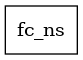

In [14]:

fcns = FCNs(1)
fcns.build((64, 128, 128, 3))

fcns.summary()

plot_model(fcns, to_file='FCNs_model.png', show_shapes=True, show_layer_names=True)

## Some loss Functions i have Tyied to use

In [15]:
import tensorflow.keras as keras


def dice_coef(y_true, y_pred, smooth):
    y_true_f = keras.flatten(y_true)
    y_pred_f = keras.flatten(y_pred)
    intersection = keras.sum(y_true_f * y_pred_f)
    dice = (2. * intersection + smooth) / (keras.sum(y_true_f) + keras.sum(y_pred_f) + smooth)
    return dice
def dice_coef_loss(y_true, y_pred, smooth):
    return 1 - dice_coef(y_true, y_pred, smooth)

def dice_loss(y_true, y_pred):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    dice = (2.0 * intersection + 1e-5) / (union + 1e-5)
    return 1.0 - dice

def soft_dice_loss(y_true, y_pred, epsilon=1e-5, class_weights=None):
    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    union = tf.reduce_sum(y_true + y_pred, axis=[1, 2, 3])

    dice = (2.0 * intersection + epsilon) / (union + epsilon)

    if class_weights is not None:
        dice = dice * class_weights

    return 1.0 - tf.reduce_mean(dice)



def binary_cross_entropy(y_true, y_pred):
  return -tf.reduce_mean(y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))


def sparse_categorical_crossentropy(y_true, y_pred):
  # Convert y_true to int32 or int64 data type
  y_true = tf.cast(y_true, dtype=tf.int32)  # Or tf.int64 if needed

  # Convert integer labels to one-hot encoded format
  y_true_onehot = tf.one_hot(y_true, depth=tf.shape(y_pred)[-1])

  # Compute cross-entropy loss
  loss = tf.reduce_mean(tf.nn.softmax_cross_entropy_with_logits(y_true_onehot, y_pred))
  return loss

def dice_loss(y_true, y_pred, epsilon=1e-7):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    dice = (2.0 * intersection + epsilon) / (union + epsilon)
    return 1.0 - dice

def dice_coef_loss(y_true, y_pred, smooth):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    dice = (2. * intersection + smooth) / (tf.keras.backend.sum(y_true_f) + tf.keras.backend.sum(y_pred_f) + smooth)
    return 1 - dice

class DiceLoss(tf.keras.losses.Loss):
  def __init__(self, smooth=1e-6, gama=2):
    super(DiceLoss, self).__init__()
    self.smooth = smooth
    self.gama = gama

  def call(self, y_true, y_pred):
    y_true, y_pred = tf.cast(y_true, dtype=tf.float32), tf.cast(y_pred, tf.float32)
    nominator = 2 * tf.reduce_sum(tf.multiply(y_pred, y_true)) + self.smooth
    denominator = tf.reduce_sum(y_pred ** self.gama) + tf.reduce_sum(y_true ** self.gama) + self.smooth
    result = 1 - tf.divide(nominator, denominator)
    return result

def ssim_loss(y_true, y_pred):
  max_val = tf.reduce_max(y_pred)
  return tf.reduce_sum(1.0 - tf.image.ssim(y_true, y_pred, max_val=max_val))

## Hyperparamers

In [19]:
# Hyperparameters
learning_rate = 1e-5
weight_decay = 1e-1
beta1 = 0.9
beta2 = 0.95
batch_per_epoch = 32
num_epochs = 2000

## Initializing 

In [20]:
# FCNs instance
fcns = FCNs(num_classes=1)


# optimizer
optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate,
    beta_1=beta1,
    beta_2=beta2,
    epsilon=1e-07,
    amsgrad=False,
    weight_decay=weight_decay,
    use_ema=True,
    ema_momentum=0.99,
    name='Adam',
)

#loss function
dice_loss_function = DiceLoss()
MeanSquaredError = tf.keras.losses.MeanSquaredError()
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

## Now Let's Teach our baby Segnet how to do semantic segmentation :)

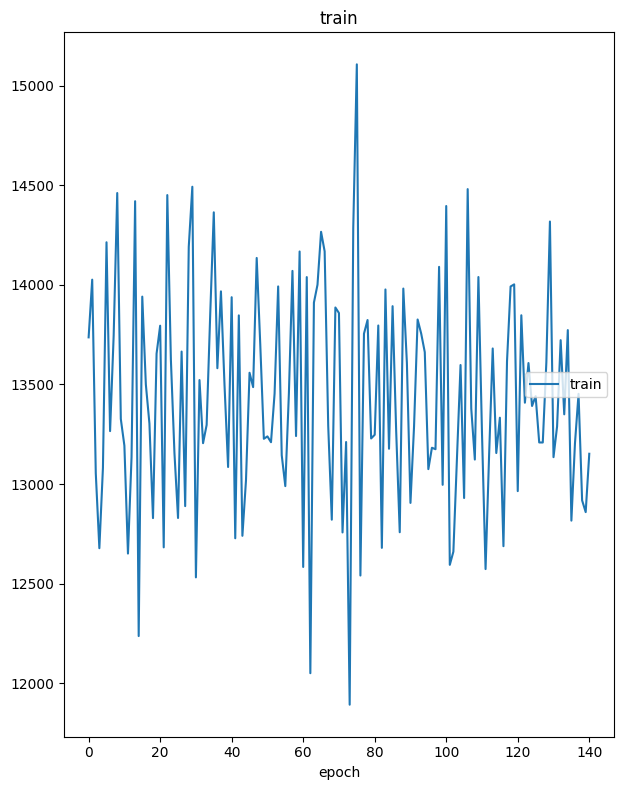

train
	train            	 (min: 11892.363, max: 15106.700, cur: 13152.002)


In [ ]:
### Training The FCNs ###
from IPython.display import clear_output
import time

@tf.function
def fcns_train_step(x, y):
    with tf.GradientTape() as tape:
        logits = fcns(x)
        loss = MeanSquaredError(y, logits)
        #loss = bce(y, logits)
        #loss = dice_loss_function(y, logits)

        grads = tape.gradient(loss, fcns.trainable_variables)
    optimizer.apply_gradients(zip(grads, fcns.trainable_variables))
    return loss , logits


# clear if it exists
if hasattr(tqdm, '_instances'): tqdm._instances.clear()

# The training loop over epochs
liveloss = PlotLosses()
for i in range(num_epochs):
    logs = {}
    for (x_batch, y_batch) in train_batches:
    # loss optimization
        loss, logits = fcns_train_step(x_batch, y_batch)
        logs["train"] = loss.numpy()
        liveloss.update(logs)
        liveloss.draw()
    print("You can Quit now !")
    time.sleep(2)

In [ ]:
tf.reduce_max(y_batch[0])
# tf.reduce_max(logits[0])
b = y_batch[0]
a = tf.image.convert_image_dtype(logits[0], tf.int64)
plt.imshow(b)


In [ ]:
#predictions
for (x_batch, y_batch) in train_batches.skip(np.random.randint(1,10)).take(18):
      logits = fcns.predict(x_batch)
      display([x_batch[0], y_batch[0], logits[0]])

i am using this section just to perform some tf operations to build up my intuitions about the model :)

In [ ]:
a = np.random.rand(64, 128, 128, 1)
b = np.random.rand(64, 128, 128, 1)

dice_loss_fun = DiceLoss()

loss = dice_loss_fun(a, b)

print(f"a ==> {a.shape}")
print(f"b ==> {b.shape}")
# print(f"loss ==> {loss.shape}")
print(loss)

In [ ]:
import numpy as np
import tensorflow as tf
import keras

# mae_loss_fun = tf.keras.losses.mean_squared_logarithmic_error
# print(tf.reduce_sum(mae_loss_fun(y_true, y_pred), [0, 1, 2]).numpy())

def ssim_loss(y_true, y_pred):
  max_val = y_pred.max()
  return tf.reduce_sum(1.0 - tf.image.ssim(y_true, y_pred, max_val=max_val))

y_true = np.random.rand(64, 128, 128, 1)
y_pred = np.random.rand(64, 128, 128, 1)

# im1 = tf.image.convert_image_dtype(im1, tf.float32)
# im2 = tf.image.convert_image_dtype(im2, tf.float32)

psnr2 = tf.image.psnr(y_true, y_pred, max_val=1.0)

def PSNR(y_true, y_pred):
    max_pixel = y_pred.max()
    mse = tf.math.reduce_mean(tf.math.square(y_pred - y_true))
    psnr = 10.0 * tf.math.log((max_pixel ** 2) / mse) / 2.303
    return tf.math.exp(-psnr)

tf.reduce_sum(ssim_loss(y_true, y_pred))
